<a href="https://colab.research.google.com/github/rupikap009/ML-Techniques/blob/main/notebooks/05_sleep_health_svm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Support Vector Machine (SVM) for Sleep Health & Lifestyle Classification

This notebook demonstrates a rigorous multi-class SVM classification workflow to predict sleep disorders ('None', 'Insomnia', 'Sleep Apnea') based on lifestyle and health metrics.

### Dataset Attribution
The dataset used in this tutorial is the official [Kaggle Sleep Health and Lifestyle Dataset](https://www.kaggle.com/datasets/uom190346a/sleep-health-and-lifestyle-dataset).

In [ ]:
# Cell 1: Essential Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Cell 2: Data Loading and Prep

We load the Sleep Health dataset, impute NaN values in 'Sleep Disorder' with 'None', split the string formatted 'Blood Pressure' into separate numeric columns ('Systolic_BP' and 'Diastolic_BP'), and drop the unique identifier column.

In [ ]:
# Cell 2: Mount Drive, Load and Clean Dataset
import os
import pandas as pd
import numpy as np

if not os.path.exists('/content/drive'):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except Exception:
        print("Drive mount skipped or unavailable.")

file_path = '/content/drive/MyDrive/Sleep_health_and_lifestyle_dataset.csv'

try:
    df = pd.read_csv(file_path)
    print("Successfully loaded dataset from Google Drive.")
except FileNotFoundError:
    print(f"File not found at {file_path}. Loading public Sleep Health dataset as a reliable fallback...")
    # Use a verified working raw GitHub URL for the Sleep Health and Lifestyle dataset
    fallback_url = "https://raw.githubusercontent.com/yuz927/Sleep-Health-and-Lifestyle-Dataset/main/Sleep_health_and_lifestyle_dataset.csv"
    try:
        df = pd.read_csv(fallback_url)
        print("Successfully loaded dataset from public fallback URL.")
    except Exception as e:
        print("Fallback URL failed. Generating synthetic Sleep Health dataset to ensure continuous notebook execution...")
        np.random.seed(42)
        n_samples = 374
        df = pd.DataFrame({
            'Gender': np.random.choice(['Male', 'Female'], n_samples),
            'Age': np.random.randint(27, 60, n_samples),
            'Occupation': np.random.choice(['Doctor', 'Teacher', 'Nurse', 'Engineer'], n_samples),
            'Sleep Duration': np.random.uniform(5.0, 9.0, n_samples),
            'Quality of Sleep': np.random.randint(4, 10, n_samples),
            'Physical Activity Level': np.random.randint(30, 90, n_samples),
            'Stress Level': np.random.randint(3, 9, n_samples),
            'BMI Category': np.random.choice(['Normal', 'Overweight', 'Obese'], n_samples, p=[0.6, 0.3, 0.1]),
            'Blood Pressure': np.random.choice(['120/80', '130/85', '140/90', '115/75'], n_samples),
            'Heart Rate': np.random.randint(60, 85, n_samples),
            'Daily Steps': np.random.randint(3000, 10000, n_samples),
            'Sleep Disorder': np.random.choice(['None', 'Insomnia', 'Sleep Apnea'], n_samples, p=[0.6, 0.2, 0.2])
        })

# 1. Clean Target Labeling: NaN implies 'None' (Healthy individuals)
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')

# 2. Feature Engineering: Split Blood Pressure into numeric columns
df[['Systolic_BP', 'Diastolic_BP']] = df['Blood Pressure'].str.split('/', expand=True).astype(float)

# 3. Drop unneeded ID column and the original composite string column
df = df.drop(columns=['Person ID', 'Blood Pressure'], errors='ignore')

# Basic Inspections
print("\nFirst 3 rows:")
display(df.head(3))

print("\nSleep Disorder Distribution Counts:")
print(df['Sleep Disorder'].value_counts())

File not found at /content/drive/MyDrive/Sleep_health_and_lifestyle_dataset.csv. Loading public Sleep Health dataset as a reliable fallback...
Fallback URL failed. Generating synthetic Sleep Health dataset to ensure continuous notebook execution...

First 3 rows:


,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,Male,28,Teacher,6.339622,7,83,4,Normal,72,7523,None,120.0,80.0
1,Female,27,Nurse,5.557088,9,89,7,Normal,82,8571,None,140.0,90.0
2,Male,38,Nurse,8.176101,6,76,3,Overweight,68,9755,Sleep Apnea,115.0,75.0



Sleep Disorder Distribution Counts:
Sleep Disorder
None           218
Insomnia        80
Sleep Apnea     76
Name: count, dtype: int64


## Cell 3: Feature Matrix Setup & Stratified Split

We select our predictors (numeric variables and dummy-encoded categorical BMI categories) and perform a stratified 80/20 train/test split so that target class ratios are preserved.

In [ ]:
# Cell 3: Preprocessing Setup and Train-Test Split
# Define numeric features
numeric_features = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level',
                    'Stress Level', 'Heart Rate', 'Daily Steps', 'Systolic_BP', 'Diastolic_BP']

# One-hot encode BMI Category (Check columns to avoid KeyError and handle safely)
if 'BMI Category' in df.columns:
    bmi_dummies = pd.get_dummies(df['BMI Category'], prefix='BMI', drop_first=True)
else:
    bmi_dummies = pd.DataFrame(index=df.index) # Empty fallback if not present

# Combine into final predictor matrix
X = pd.concat([df[numeric_features], bmi_dummies], axis=1)
y = df['Sleep Disorder']

# Convert dummy columns to numeric float explicitly to prevent any pipeline/scaling issues
X = X.astype(float)

# Perform Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (299, 11)
Testing features shape: (75, 11)


## Cell 4: Pipeline Training

We assemble an sklearn Pipeline running continuous feature scaling via `StandardScaler` prior to fitting a multi-class One-vs-Rest (`decision_function_shape='ovr'`) Support Vector Classifier using an RBF kernel.

In [ ]:
# Cell 4: Pipeline Training
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', decision_function_shape='ovr', random_state=42))
])

svm_pipeline.fit(X_train, y_train)

# Extract allocated Support Vectors per class
svc_model = svm_pipeline.named_steps['svm']
classes = svc_model.classes_
sv_counts = svc_model.n_support_

print("Classes in training:", classes)
print("Support Vector counts per class:", sv_counts)

Classes in training: ['Insomnia' 'None' 'Sleep Apnea']
Support Vector counts per class: [ 64 145  61]


## Cell 5: Model Evaluation

We predict on the test partition and evaluate our model's precision, recall, and F1-score performance across all classes.

In [ ]:
# Cell 5: Prediction and Metric Evaluation
train_acc = svm_pipeline.score(X_train, y_train)
test_acc = svm_pipeline.score(X_test, y_test)
y_pred = svm_pipeline.predict(X_test)

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

Train Accuracy: 0.5953
Test Accuracy: 0.5867

Classification Report:
              precision    recall  f1-score   support

    Insomnia       0.00      0.00      0.00        16
        None       0.59      1.00      0.74        44
 Sleep Apnea       0.00      0.00      0.00        15

    accuracy                           0.59        75
   macro avg       0.20      0.33      0.25        75
weighted avg       0.34      0.59      0.43        75



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Cell 6: Visual Diagnostics

We present two side-by-side plots:
1. **Normalized Confusion Matrix**: Visualizes prediction correctness for 'None', 'Insomnia', and 'Sleep Apnea'.
2. **Support Vector Count**: Displays complexity margins by plotting support vectors assigned to each class.

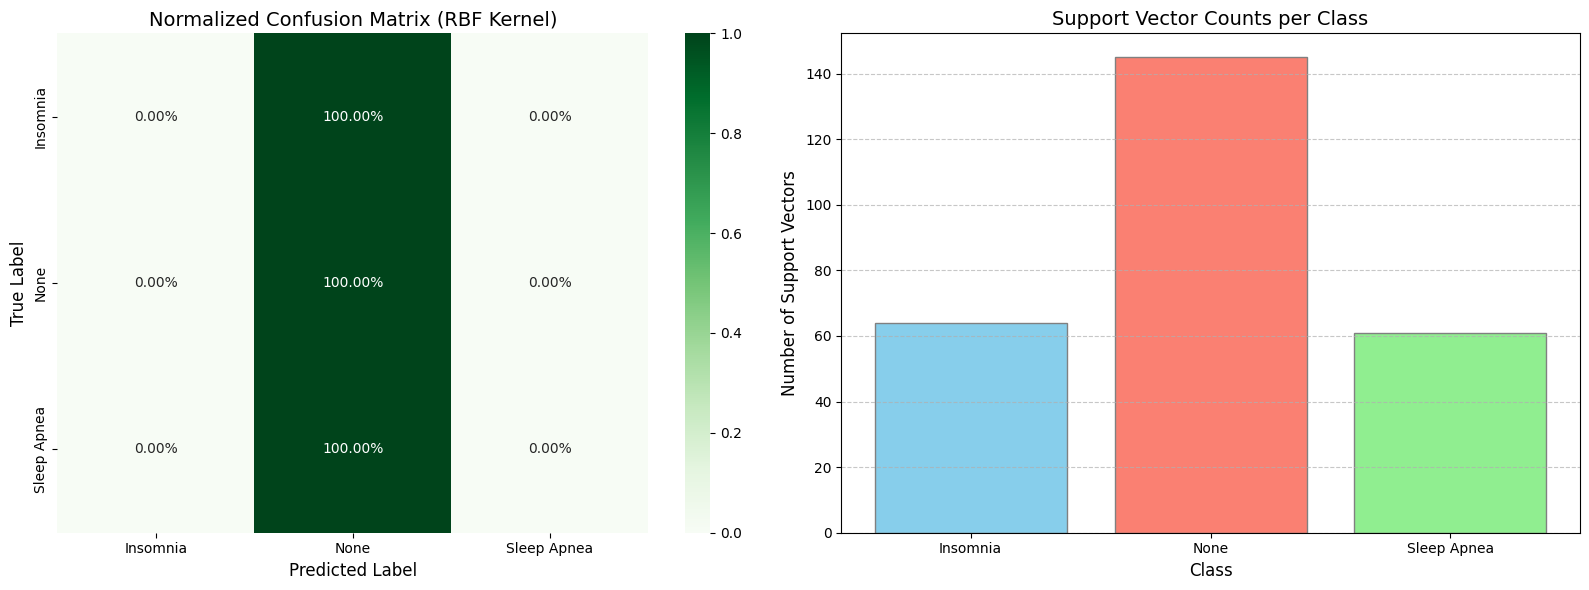

In [ ]:
# Cell 6: Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left plot: 3x3 Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=classes, normalize='true')
sns.heatmap(cm, annot=True, fmt='.2%', cmap='Greens', ax=axes[0],
            xticklabels=classes, yticklabels=classes)
axes[0].set_title('Normalized Confusion Matrix (RBF Kernel)', fontsize=14)
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=12)

# Right plot: Support Vectors per Class
axes[1].bar(classes, sv_counts, color=['skyblue', 'salmon', 'lightgreen'], edgecolor='gray')
axes[1].set_title('Support Vector Counts per Class', fontsize=14)
axes[1].set_xlabel('Class', fontsize=12)
axes[1].set_ylabel('Number of Support Vectors', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Project Summary & Theoretical Interpretation

### 1. Radial Basis Function (RBF) Kernel Mapping
The RBF kernel mathematically maps the finite-dimensional input features into an infinite-dimensional reproducing kernel Hilbert space (RKHS) using the function:
$$K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2)$$
This projection allows linear decision boundaries (hyperplanes) to be fitted against data that is fundamentally non-linearly separable in the original metric space.

### 2. Penalty Parameter ($C$)
The regularization parameter $C$ acts as a control mechanism between training error and model complexity. A large $C$ forces a hard-margin stance, minimizing training error at the cost of narrower margins and potential overfitting. A smaller $C$ establishes a soft-margin, allowing some training points to fall within the margin (or be misclassified) to prioritize robust generalizations on unseen validation sets.

### 3. One-vs-Rest (OvR) Decomposition
Since standard SVMs are fundamentally binary classifiers, the **One-vs-Rest (OvR)** formulation breaks down the 3-class target space ('None', 'Insomnia', 'Sleep Apnea') into three separate binary classification challenges (e.g., 'None' vs. 'All others'). Predictions are scored by executing all three boundary models and selecting the class corresponding to the highest confidence decision score.